# 02 - Preprocessing (step 1)
Only: drop the exported index column, clean `Ram`, clean `Weight`. **No other columns are touched.**

In [1]:
# Import pandas
import pandas as pd
pd.set_option('display.max_columns', None)

# Load the raw dataset
df = pd.read_csv('laptop_data.csv')

## Record the state before preprocessing

In [2]:
# Save the original shape and dtypes so we can compare afterwards
shape_before = df.shape
print('Shape before:', shape_before)
print('Ram dtype before:', df['Ram'].dtype)
print('Weight dtype before:', df['Weight'].dtype)

Shape before: (1303, 12)
Ram dtype before: str
Weight dtype before: str


## 1. Remove the exported index column

In [3]:
# Confirm the column exists and is just a copy of 0..n-1 before dropping it
if 'Unnamed: 0' in df.columns:
    is_index_copy = (df['Unnamed: 0'] == pd.RangeIndex(len(df))).all()
    print("'Unnamed: 0' exists; equals 0..n-1:", is_index_copy)
    if is_index_copy:
        df = df.drop(columns=['Unnamed: 0'])
        print("Dropped 'Unnamed: 0'")
else:
    print("'Unnamed: 0' not found; nothing dropped")

'Unnamed: 0' exists; equals 0..n-1: True
Dropped 'Unnamed: 0'


## 2 & 3. Inspect `Ram` and `Weight` formats before converting

In [4]:
# Every Ram value should look like '<digits>GB'
bad_ram = df.loc[~df['Ram'].str.fullmatch(r'\d+GB'), 'Ram']
print('Unique Ram values:', df['Ram'].unique().tolist())
print('Unexpected Ram values:', bad_ram.unique().tolist())

# Every Weight value should look like '<number>kg'
bad_weight = df.loc[~df['Weight'].str.fullmatch(r'\d+(\.\d+)?kg'), 'Weight']
print('Unexpected Weight values:', bad_weight.unique().tolist())

# Stop here instead of silently coercing if anything unexpected shows up
assert bad_ram.empty and bad_weight.empty, 'Unexpected formats found - inspect before converting'

Unique Ram values: ['8GB', '16GB', '4GB', '2GB', '12GB', '6GB', '32GB', '24GB', '64GB']
Unexpected Ram values: []
Unexpected Weight values: []


## 2. Clean `Ram`: remove 'GB' and convert to int

In [5]:
# '8GB' -> 8
df['Ram'] = df['Ram'].str.replace('GB', '', regex=False).astype(int)

## 3. Clean `Weight`: remove 'kg' and convert to float

In [6]:
# '1.37kg' -> 1.37
df['Weight'] = df['Weight'].str.replace('kg', '', regex=False).astype(float)

## 5. Verify the result

In [7]:
df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080


In [8]:
print(df.shape)

(1303, 11)


In [9]:
print(df.dtypes)

Company                 str
TypeName                str
Inches              float64
ScreenResolution        str
Cpu                     str
Ram                   int64
Memory                  str
Gpu                     str
OpSys                   str
Weight              float64
Price               float64
dtype: object


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1303 non-null   str    
 1   TypeName          1303 non-null   str    
 2   Inches            1303 non-null   float64
 3   ScreenResolution  1303 non-null   str    
 4   Cpu               1303 non-null   str    
 5   Ram               1303 non-null   int64  
 6   Memory            1303 non-null   str    
 7   Gpu               1303 non-null   str    
 8   OpSys             1303 non-null   str    
 9   Weight            1303 non-null   float64
 10  Price             1303 non-null   float64
dtypes: float64(3), int64(1), str(7)
memory usage: 112.1 KB


## 6. Check `Ram` and `Weight` directly

In [11]:
print('Ram dtype:', df['Ram'].dtype)
print('Weight dtype:', df['Weight'].dtype)
print('\nFirst 10 Ram values:', df['Ram'].head(10).tolist())
print('First 10 Weight values:', df['Weight'].head(10).tolist())

Ram dtype: int64
Weight dtype: float64

First 10 Ram values: [8, 8, 8, 16, 8, 4, 16, 8, 16, 8]
First 10 Weight values: [1.37, 1.34, 1.86, 1.83, 1.37, 2.1, 2.04, 1.34, 1.3, 1.6]


## 7. Were any missing values introduced?

In [12]:
print(df[['Ram', 'Weight']].isnull().sum())

Ram       0
Weight    0
dtype: int64


## 8. Did the number of rows change?

In [13]:
# Rows should be unchanged; columns should drop by exactly 1
print('Shape before:', shape_before)
print('Shape after: ', df.shape)
print('Row count unchanged:', df.shape[0] == shape_before[0])

Shape before: (1303, 12)
Shape after:  (1303, 11)
Row count unchanged: True


## Target distribution (`Price`)

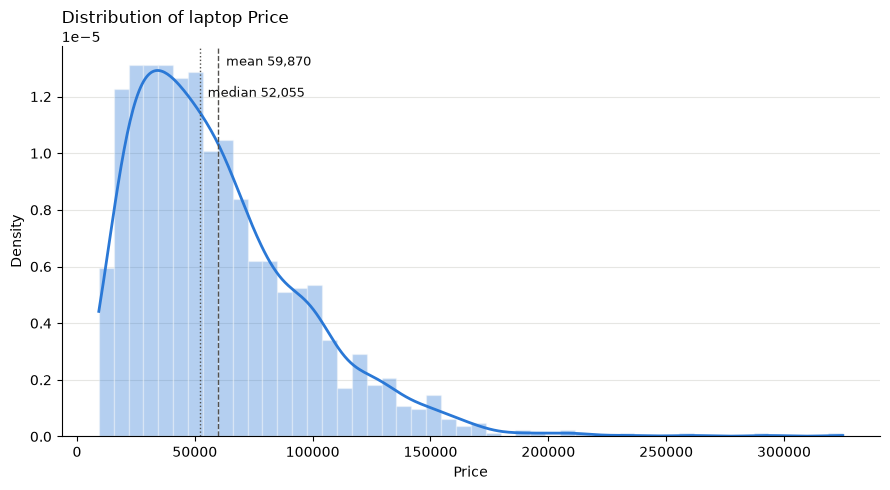

Skewness: 1.521


In [14]:
# Distribution plot of the target: histogram (density) + KDE curve
# (same idea as seaborn's old distplot, using matplotlib + scipy)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

price = df['Price']
kde = gaussian_kde(price)
xs = np.linspace(price.min(), price.max(), 500)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(price, bins=50, density=True, color='#2a78d6', alpha=0.35, edgecolor='#fcfcfb', linewidth=1)
ax.plot(xs, kde(xs), color='#2a78d6', linewidth=2)

# Mark mean and median to show the skew
ax.axvline(price.mean(), color='#52514e', linestyle='--', linewidth=1)
ax.axvline(price.median(), color='#52514e', linestyle=':', linewidth=1)
ax.text(price.mean(), ax.get_ylim()[1] * 0.95, f'  mean {price.mean():,.0f}', color='#0b0b0b', fontsize=9)
ax.text(price.median(), ax.get_ylim()[1] * 0.87, f'  median {price.median():,.0f}', color='#0b0b0b', fontsize=9)

ax.set_title('Distribution of laptop Price', loc='left')
ax.set_xlabel('Price')
ax.set_ylabel('Density')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('price_distribution.png', dpi=120)
plt.show()

print('Skewness:', round(price.skew(), 3))

## Number of products per company

Company
Dell         297
Lenovo       297
HP           274
Asus         158
Acer         103
MSI           54
Toshiba       48
Apple         21
Samsung        9
Razer          7
Mediacom       7
Microsoft      6
Xiaomi         4
Vero           4
Chuwi          3
Google         3
Fujitsu        3
LG             3
Huawei         2
Name: count, dtype: int64


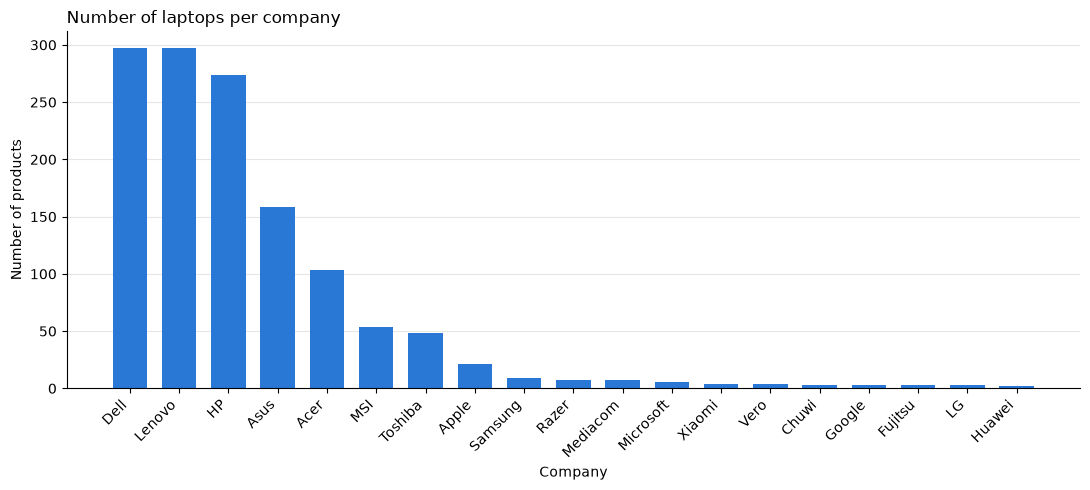

In [15]:
# Number of laptops (rows) per company, sorted from most to fewest
company_counts = df['Company'].value_counts()
print(company_counts)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(company_counts.index, company_counts.values, color='#2a78d6', width=0.7)

ax.set_title('Number of laptops per company', loc='left')
ax.set_xlabel('Company')
ax.set_ylabel('Number of products')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('company_counts.png', dpi=120)
plt.show()

## Average price per company

               mean  count
Company                   
Razer      178282.0      7
LG         111835.0      3
MSI         92116.0     54
Google      89386.0      3
Microsoft   85904.0      6
Apple       83340.0     21
Huawei      75871.0      2
Samsung     75308.0      9
Toshiba     67549.0     48
Dell        63194.0    297
Xiaomi      60391.0      4
Asus        58830.0    158
Lenovo      57883.0    297
HP          56891.0    274
Fujitsu     38841.0      3
Acer        33395.0    103
Chuwi       16746.0      3
Mediacom    15718.0      7
Vero        11584.0      4


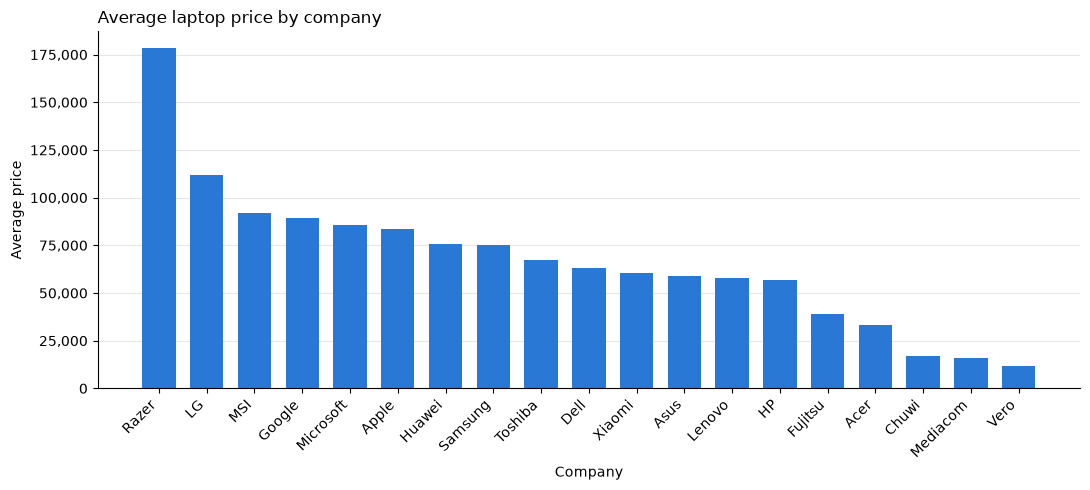

In [16]:
# Average price per company, sorted from most to least expensive
# (count shown alongside, since averages from 2-3 laptops are unreliable)
company_price = df.groupby('Company')['Price'].agg(['mean', 'count']).sort_values('mean', ascending=False)
print(company_price.round(0))

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(company_price.index, company_price['mean'], color='#2a78d6', width=0.7)

ax.set_title('Average laptop price by company', loc='left')
ax.set_xlabel('Company')
ax.set_ylabel('Average price')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('company_avg_price.png', dpi=120)
plt.show()

## Number of laptops per TypeName

Number of distinct TypeName values: 6
TypeName
Notebook              727
Gaming                205
Ultrabook             196
2 in 1 Convertible    121
Workstation            29
Netbook                25
Name: count, dtype: int64


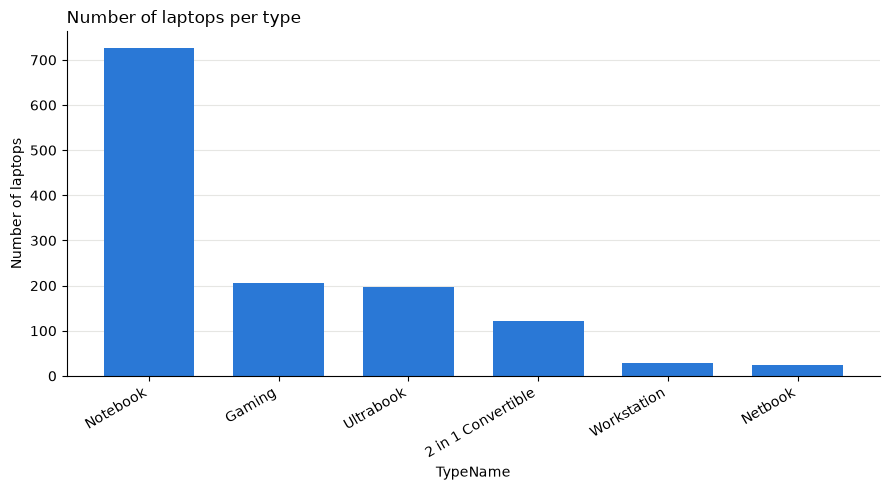

In [17]:
# How many distinct laptop types exist, and how many laptops of each
print('Number of distinct TypeName values:', df['TypeName'].nunique())
type_counts = df['TypeName'].value_counts()
print(type_counts)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(type_counts.index, type_counts.values, color='#2a78d6', width=0.7)

ax.set_title('Number of laptops per type', loc='left')
ax.set_xlabel('TypeName')
ax.set_ylabel('Number of laptops')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('typename_counts.png', dpi=120)
plt.show()

## Price by TypeName (with average)

                        mean    median      min       max  count
TypeName                                                        
Workstation         121498.0  110018.0  72940.0  233846.0     29
Gaming               92248.0   79536.0  37243.0  324955.0    205
Ultrabook            82490.0   79867.0  26587.0  165168.0    196
2 in 1 Convertible   68326.0   63883.0  14652.0  150463.0    121
Notebook             41669.0   36816.0  10443.0  261019.0    727
Netbook              33898.0   18115.0   9271.0  101658.0     25


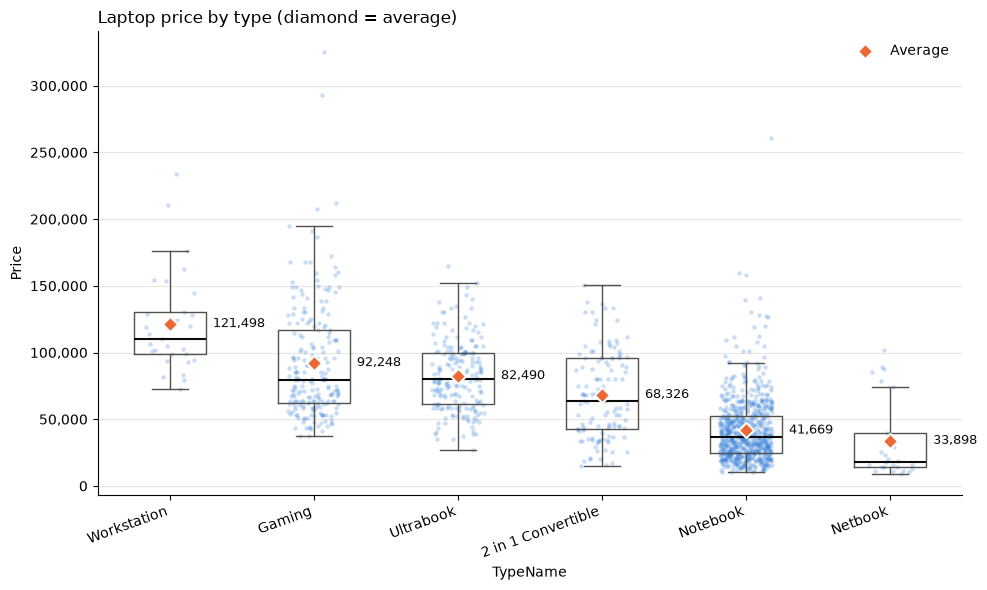

In [18]:
# Price distribution per TypeName, with the average marked
# Types ordered from highest to lowest average price
type_stats = df.groupby('TypeName')['Price'].agg(['mean', 'median', 'min', 'max', 'count']).sort_values('mean', ascending=False)
print(type_stats.round(0))

order = type_stats.index.tolist()
groups = [df.loc[df['TypeName'] == t, 'Price'] for t in order]
positions = np.arange(1, len(order) + 1)

fig, ax = plt.subplots(figsize=(10, 6))

# Each laptop as a faint dot (small horizontal jitter so points don't stack)
rng = np.random.default_rng(42)
for pos, g in zip(positions, groups):
    ax.scatter(pos + rng.uniform(-0.18, 0.18, len(g)), g, s=10, color='#2a78d6', alpha=0.25, linewidths=0)

# Box = middle 50% of prices, line = median
ax.boxplot(groups, positions=positions, widths=0.5, showfliers=False,
           medianprops=dict(color='#0b0b0b', linewidth=1.5),
           boxprops=dict(color='#52514e'), whiskerprops=dict(color='#52514e'), capprops=dict(color='#52514e'))

# Average marked with a diamond and labelled
means = type_stats['mean'].values
ax.scatter(positions, means, marker='D', s=60, color='#eb6834', edgecolors='#fcfcfb', linewidths=1.5, zorder=3, label='Average')
for pos, m in zip(positions, means):
    ax.text(pos + 0.3, m, f'{m:,.0f}', va='center', fontsize=9, color='#0b0b0b')

ax.set_xticks(positions, order, rotation=20, ha='right')
ax.set_title('Laptop price by type (diamond = average)', loc='left')
ax.set_xlabel('TypeName')
ax.set_ylabel('Price')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper right')
plt.tight_layout()
fig.savefig('typename_price.png', dpi=120)
plt.show()

## Screen size distribution (`Inches`)

count    1303.00
mean       15.02
std         1.43
min        10.10
25%        14.00
50%        15.60
75%        15.60
max        18.40
Name: Inches, dtype: float64

Most common sizes:
Inches
15.6    665
14.0    197
13.3    164
17.3    164
12.5     39
11.6     33
12.0      6
13.5      6
Name: count, dtype: int64


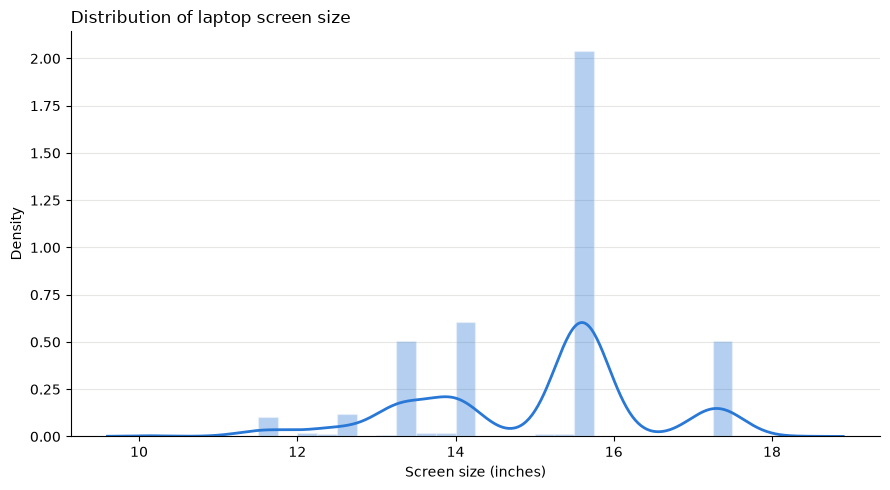

In [19]:
# Distribution plot of screen size (Inches): histogram (density) + KDE curve
inches = df['Inches']
print(inches.describe().round(2))
print('\nMost common sizes:')
print(inches.value_counts().head(8))

kde = gaussian_kde(inches)
xs = np.linspace(inches.min() - 0.5, inches.max() + 0.5, 500)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(inches, bins=np.arange(10, 19, 0.25), density=True, color='#2a78d6', alpha=0.35, edgecolor='#fcfcfb', linewidth=1)
ax.plot(xs, kde(xs), color='#2a78d6', linewidth=2)

ax.set_title('Distribution of laptop screen size', loc='left')
ax.set_xlabel('Screen size (inches)')
ax.set_ylabel('Density')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('inches_distribution.png', dpi=120)
plt.show()

## Inches vs Price

Correlation (Inches vs Price): 0.068


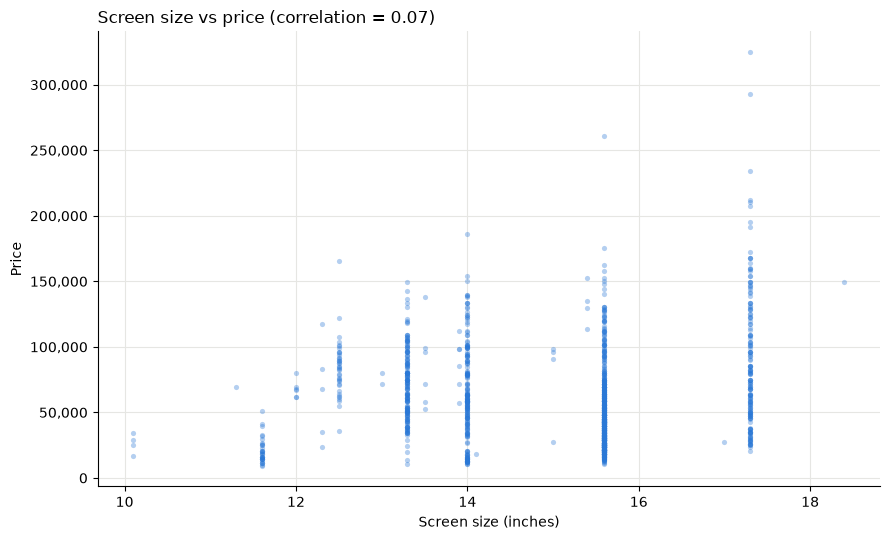

           mean  count
Inches                
11.6    20972.0     33
12.5    84369.0     39
13.3    70986.0    164
14.0    64057.0    197
15.6    48131.0    665
17.3    89141.0    164


In [20]:
# Scatter plot: screen size vs price
# Correlation tells us how strongly (linearly) the two move together
corr = df['Inches'].corr(df['Price'])
print('Correlation (Inches vs Price):', round(corr, 3))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(df['Inches'], df['Price'], s=14, color='#2a78d6', alpha=0.35, linewidths=0)

ax.set_title(f'Screen size vs price (correlation = {corr:.2f})', loc='left')
ax.set_xlabel('Screen size (inches)')
ax.set_ylabel('Price')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('inches_vs_price.png', dpi=120)
plt.show()

# Average price at each common screen size
print(df.groupby('Inches')['Price'].agg(['mean', 'count']).query('count >= 20').round(0))

## Feature engineering: `Touchscreen` (from ScreenResolution)

In [21]:
# New feature: Touchscreen = 1 if 'Touchscreen' appears in ScreenResolution, else 0
# case=False so 'touchscreen' / 'TouchScreen' would also be caught
df['Touchscreen'] = df['ScreenResolution'].str.contains('Touchscreen', case=False).astype(int)

# Verify: counts of 0/1, dtype, and no missing values introduced
print(df['Touchscreen'].value_counts())
print('dtype:', df['Touchscreen'].dtype)
print('Missing values:', df['Touchscreen'].isnull().sum())
print('Shape:', df.shape)

# Spot-check a few rows of each kind against the original text
df[['ScreenResolution', 'Touchscreen']].groupby('Touchscreen').head(3)

Touchscreen
0    1111
1     192
Name: count, dtype: int64
dtype: int64
Missing values: 0
Shape: (1303, 12)


,ScreenResolution,Touchscreen
0,IPS Panel Retina Display 2560x1600,0
1,1440x900,0
2,Full HD 1920x1080,0
19,IPS Panel Full HD / Touchscreen 1920x1080,1
23,Full HD / Touchscreen 1920x1080,1
33,Touchscreen / Quad HD+ 3200x1800,1


In [22]:
# Quick look: does a touchscreen relate to price?
print(df.groupby('Touchscreen')['Price'].agg(['mean', 'median', 'count']).round(0))

                mean   median  count
Touchscreen                         
0            56911.0  48964.0   1111
1            76995.0  74539.0    192


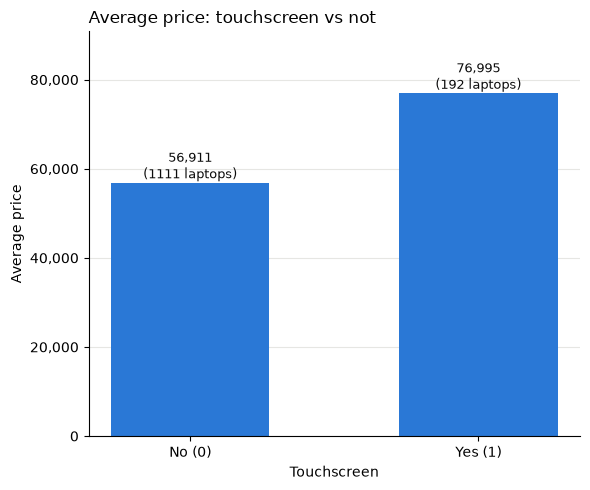

In [23]:
# Bar plot: average price for non-touchscreen (0) vs touchscreen (1) laptops
touch_price = df.groupby('Touchscreen')['Price'].agg(['mean', 'count'])

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(['No (0)', 'Yes (1)'], touch_price['mean'], color='#2a78d6', width=0.55)

# Label each bar with its average and number of laptops
for bar, (m, n) in zip(bars, touch_price.values):
    ax.text(bar.get_x() + bar.get_width() / 2, m, f'{m:,.0f}\n({int(n)} laptops)',
            ha='center', va='bottom', fontsize=9, color='#0b0b0b')

ax.set_title('Average price: touchscreen vs not', loc='left')
ax.set_xlabel('Touchscreen')
ax.set_ylabel('Average price')
ax.set_ylim(0, touch_price['mean'].max() * 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('touchscreen_price.png', dpi=120)
plt.show()

## Feature engineering: `Ips` (from ScreenResolution)

In [24]:
# New feature: Ips = 1 if 'IPS' appears in ScreenResolution, else 0
df['Ips'] = df['ScreenResolution'].str.contains('IPS', case=False).astype(int)

# Verify: counts of 0/1, dtype, and no missing values introduced
print(df['Ips'].value_counts())
print('dtype:', df['Ips'].dtype)
print('Missing values:', df['Ips'].isnull().sum())
print('Shape:', df.shape)

# Quick look: does an IPS panel relate to price?
print(df.groupby('Ips')['Price'].agg(['mean', 'median', 'count']).round(0))

# Spot-check a few rows of each kind against the original text
df[['ScreenResolution', 'Ips']].groupby('Ips').head(3)

Ips
0    938
1    365
Name: count, dtype: int64
dtype: int64
Missing values: 0
Shape: (1303, 13)
        mean   median  count
Ips                         
0    54013.0  45168.0    938
1    74922.0  67133.0    365


,ScreenResolution,Ips
0,IPS Panel Retina Display 2560x1600,1
1,1440x900,0
2,Full HD 1920x1080,0
3,IPS Panel Retina Display 2880x1800,1
4,IPS Panel Retina Display 2560x1600,1
5,1366x768,0


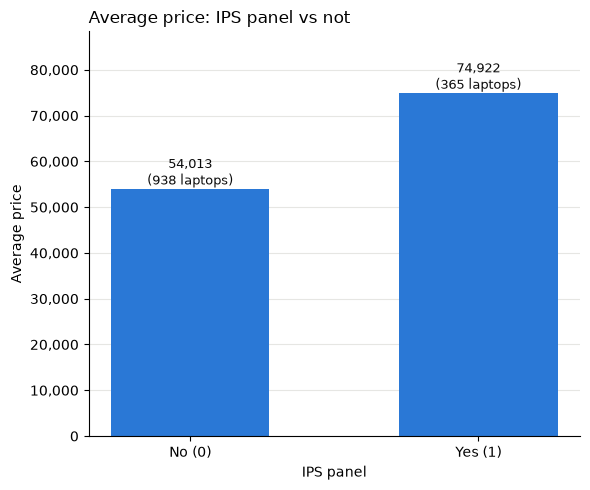

In [25]:
# Bar plot: average price for non-IPS (0) vs IPS (1) laptops
ips_price = df.groupby('Ips')['Price'].agg(['mean', 'count'])

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(['No (0)', 'Yes (1)'], ips_price['mean'], color='#2a78d6', width=0.55)

# Label each bar with its average and number of laptops
for bar, (m, n) in zip(bars, ips_price.values):
    ax.text(bar.get_x() + bar.get_width() / 2, m, f'{m:,.0f}\n({int(n)} laptops)',
            ha='center', va='bottom', fontsize=9, color='#0b0b0b')

ax.set_title('Average price: IPS panel vs not', loc='left')
ax.set_xlabel('IPS panel')
ax.set_ylabel('Average price')
ax.set_ylim(0, ips_price['mean'].max() * 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('ips_price.png', dpi=120)
plt.show()

## Feature engineering: `X_res` and `Y_res` (from ScreenResolution)

In [26]:
# Sanity check: every ScreenResolution should contain exactly one 'x' (the one in e.g. 1920x1080)
print("Rows with not exactly one 'x':", (df['ScreenResolution'].str.count('x') != 1).sum())

# Split on the first 'x' into two parts
res_split = df['ScreenResolution'].str.split('x', n=1, expand=True)
print(res_split.head())

Rows with not exactly one 'x': 0
                               0     1
0  IPS Panel Retina Display 2560  1600
1                           1440   900
2                   Full HD 1920  1080
3  IPS Panel Retina Display 2880  1800
4  IPS Panel Retina Display 2560  1600


In [27]:
# Left part still has text ('IPS Panel Full HD 1920') -> keep only the trailing number
df['X_res'] = res_split[0].str.extract(r'(\d+)$')[0].astype(int)
# Right part is already just the number ('1080')
df['Y_res'] = res_split[1].astype(int)

# Verify: dtypes, missing values, shape, and a side-by-side check with the original text
print(df[['X_res', 'Y_res']].dtypes)
print('Missing values:', df[['X_res', 'Y_res']].isnull().sum().to_dict())
print('Shape:', df.shape)
df[['ScreenResolution', 'X_res', 'Y_res']].head(8)

X_res    int64
Y_res    int64
dtype: object
Missing values: {'X_res': 0, 'Y_res': 0}
Shape: (1303, 15)


,ScreenResolution,X_res,Y_res
0,IPS Panel Retina Display 2560x1600,2560,1600
1,1440x900,1440,900
2,Full HD 1920x1080,1920,1080
3,IPS Panel Retina Display 2880x1800,2880,1800
4,IPS Panel Retina Display 2560x1600,2560,1600
5,1366x768,1366,768
6,IPS Panel Retina Display 2880x1800,2880,1800
7,1440x900,1440,900


In [28]:
# Distinct resolutions and how X_res / Y_res relate to price
print(df.groupby(['X_res', 'Y_res']).size().sort_values(ascending=False))
print('\nCorrelation with Price:')
print(df[['X_res', 'Y_res']].corrwith(df['Price']).round(3))

X_res  Y_res
1920   1080     841
1366   768      308
3840   2160      43
3200   1800      27
1600   900       23
2560   1440      23
2256   1504       6
2304   1440       6
2560   1600       6
1920   1200       5
1440   900        4
2400   1600       4
2880   1800       4
2160   1440       2
2736   1824       1
dtype: int64

Correlation with Price:
X_res    0.557
Y_res    0.553
dtype: float64


In [29]:
# 5 random rows to check the current state of the data
df.sample(5)

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Touchscreen,Ips,X_res,Y_res
461,Acer,Netbook,11.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,4,128GB SSD,Intel HD Graphics 400,Windows 10,1.40,23176.8000,0,0,1366,768
43,Acer,Notebook,15.6,IPS Panel Full HD 1920x1080,Intel Core i5 8250U 1.6GHz,4,256GB SSD,Intel UHD Graphics 620,Windows 10,2.20,36336.9600,0,1,1920,1080
758,Dell,Gaming,15.6,IPS Panel 4K Ultra HD 3840x2160,Intel Core i7 7700HQ 2.8GHz,16,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,4.42,152859.7872,0,1,3840,2160
639,Dell,Notebook,15.6,4K Ultra HD / Touchscreen 3840x2160,Intel Core i7 7700HQ 2.8GHz,16,1TB SSD,Nvidia GeForce GTX 1050,Windows 10,2.06,127818.7200,1,0,3840,2160
1071,HP,Notebook,15.6,1366x768,Intel Core i5 6200U 2.3GHz,4,500GB HDD,Intel HD Graphics 520,Windows 10,2.31,63882.7200,0,0,1366,768


## Correlation of numeric columns with Price

In [30]:
# Pearson correlation of every numeric column with Price, strongest first
price_corr = df.corr(numeric_only=True)['Price'].drop('Price').sort_values(ascending=False)
print(price_corr.round(3))

Ram            0.743
X_res          0.557
Y_res          0.553
Ips            0.252
Weight         0.210
Touchscreen    0.191
Inches         0.068
Name: Price, dtype: float64


## Feature engineering: `ppi` (pixels per inch)

In [31]:
# PPI = diagonal resolution in pixels / diagonal size in inches
#     = sqrt(X_res^2 + Y_res^2) / Inches
# Inches has no zeros (min 10.1), so the division is safe
df['ppi'] = np.sqrt(df['X_res'] ** 2 + df['Y_res'] ** 2) / df['Inches']

# Verify: dtype, missing values, range, shape
print('dtype:', df['ppi'].dtype)
print('Missing values:', df['ppi'].isnull().sum())
print('Shape:', df.shape)
print(df['ppi'].describe().round(2))

# Correlation with Price, compared with the columns it was built from
print('\nCorrelation with Price:')
print(df[['ppi', 'X_res', 'Y_res', 'Inches']].corrwith(df['Price']).round(3))

df[['Inches', 'X_res', 'Y_res', 'ppi']].head()

dtype: float64
Missing values: 0
Shape: (1303, 16)
count    1303.00
mean      146.64
std        43.12
min        90.58
25%       127.34
50%       141.21
75%       157.35
max       352.47
Name: ppi, dtype: float64

Correlation with Price:
ppi       0.473
X_res     0.557
Y_res     0.553
Inches    0.068
dtype: float64


,Inches,X_res,Y_res,ppi
0,13.3,2560,1600,226.983005
1,13.3,1440,900,127.677940
2,15.6,1920,1080,141.211998
3,15.4,2880,1800,220.534624
4,13.3,2560,1600,226.983005


## Drop `ScreenResolution`
All useful information has been extracted into `Touchscreen`, `Ips`, `X_res`, `Y_res` and `ppi`.

In [32]:
# Drop ScreenResolution (only if present, so re-running is safe)
print('Shape before:', df.shape)
df = df.drop(columns=['ScreenResolution'], errors='ignore')
print('Shape after: ', df.shape)
print('ScreenResolution still present:', 'ScreenResolution' in df.columns)
print(list(df.columns))
df.head()

Shape before: (1303, 16)
Shape after:  (1303, 15)
ScreenResolution still present: False
['Company', 'TypeName', 'Inches', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price', 'Touchscreen', 'Ips', 'X_res', 'Y_res', 'ppi']


,Company,TypeName,Inches,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Touchscreen,Ips,X_res,Y_res,ppi
0,Apple,Ultrabook,13.3,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832,0,1,2560,1600,226.983005
1,Apple,Ultrabook,13.3,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232,0,0,1440,900,127.677940
2,HP,Notebook,15.6,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000,0,0,1920,1080,141.211998
3,Apple,Ultrabook,15.4,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360,0,1,2880,1800,220.534624
4,Apple,Ultrabook,13.3,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080,0,1,2560,1600,226.983005


## Drop `Inches`, `X_res`, `Y_res`
Their information is combined in `ppi`.

In [33]:
# Drop the columns that ppi was built from (errors="ignore" makes re-running safe)
print('Shape before:', df.shape)
df = df.drop(columns=['Inches', 'X_res', 'Y_res'], errors='ignore')
print('Shape after: ', df.shape)
print(list(df.columns))
df.head()

Shape before: (1303, 15)
Shape after:  (1303, 12)
['Company', 'TypeName', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price', 'Touchscreen', 'Ips', 'ppi']


,Company,TypeName,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Touchscreen,Ips,ppi
0,Apple,Ultrabook,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832,0,1,226.983005
1,Apple,Ultrabook,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232,0,0,127.677940
2,HP,Notebook,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000,0,0,141.211998
3,Apple,Ultrabook,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360,0,1,220.534624
4,Apple,Ultrabook,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080,0,1,226.983005


## Feature engineering: `Cpu Name` and `Cpu brand` (from Cpu)

In [34]:
# Step 1: first three words of Cpu -> 'Cpu Name'  (e.g. 'Intel Core i5 7200U 2.5GHz' -> 'Intel Core i5')
df['Cpu Name'] = df['Cpu'].apply(lambda text: ' '.join(text.split()[0:3]))
print('Distinct Cpu Name values:', df['Cpu Name'].nunique())
df[['Cpu', 'Cpu Name']].head()

Distinct Cpu Name values: 40


,Cpu,Cpu Name
0,Intel Core i5 2.3GHz,Intel Core i5
1,Intel Core i5 1.8GHz,Intel Core i5
2,Intel Core i5 7200U 2.5GHz,Intel Core i5
3,Intel Core i7 2.7GHz,Intel Core i7
4,Intel Core i5 3.1GHz,Intel Core i5


In [35]:
# Step 2: classify Cpu Name into 5 categories -> 'Cpu brand'
def fetch_processor(text):
    if text in ('Intel Core i7', 'Intel Core i5', 'Intel Core i3'):
        return text
    elif text.split()[0] == 'Intel':
        return 'Other Intel Processor'
    else:
        return 'AMD Processor'

df['Cpu brand'] = df['Cpu Name'].apply(fetch_processor)

# Verify: category counts, missing values, shape
print(df['Cpu brand'].value_counts())
print('Missing values:', df['Cpu brand'].isnull().sum())
print('Shape:', df.shape)

# Check what fell into the "anything else" bucket that is not actually AMD
print('\nNon-AMD rows labelled AMD Processor:')
print(df.loc[(df['Cpu brand'] == 'AMD Processor') & ~df['Cpu'].str.startswith('AMD'), ['Company', 'Cpu']])

Cpu brand
Intel Core i7            527
Intel Core i5            423
Other Intel Processor    154
Intel Core i3            136
AMD Processor             63
Name: count, dtype: int64
Missing values: 0
Shape: (1303, 14)

Non-AMD rows labelled AMD Processor:
      Company                            Cpu
1191  Samsung  Samsung Cortex A72&A53 2.0GHz


In [36]:
# Spot-check one example of each category
df.groupby('Cpu brand').head(1)[['Cpu', 'Cpu Name', 'Cpu brand']]

,Cpu,Cpu Name,Cpu brand
0,Intel Core i5 2.3GHz,Intel Core i5,Intel Core i5
3,Intel Core i7 2.7GHz,Intel Core i7,Intel Core i7
5,AMD A9-Series 9420 3GHz,AMD A9-Series 9420,AMD Processor
11,Intel Core i3 6006U 2GHz,Intel Core i3,Intel Core i3
14,Intel Core M m3 1.2GHz,Intel Core M,Other Intel Processor


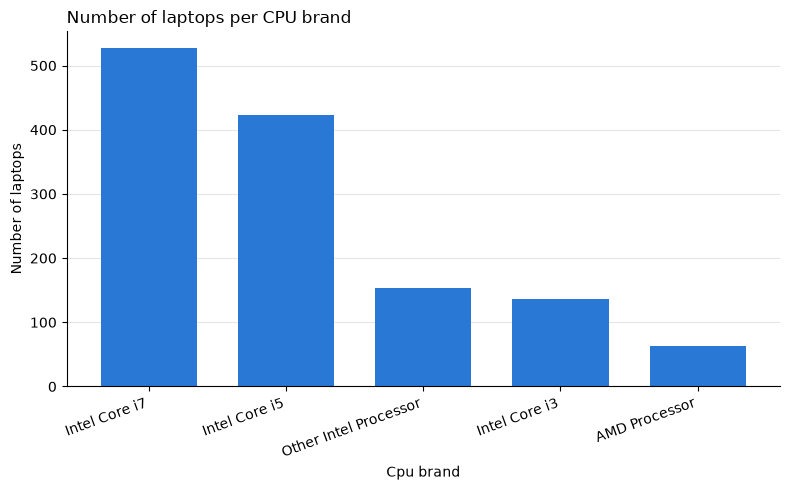

In [37]:
# Value counts of Cpu brand as a bar plot
ax = df['Cpu brand'].value_counts().plot(kind='bar', figsize=(8, 5), color='#2a78d6', width=0.7)

ax.set_title('Number of laptops per CPU brand', loc='left')
ax.set_xlabel('Cpu brand')
ax.set_ylabel('Number of laptops')
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('cpu_brand_counts.png', dpi=120)
plt.show()

                          mean   median  count
Cpu brand                                     
Intel Core i7          85023.0  78647.0    527
Intel Core i5          54080.0  50882.0    423
AMD Processor          29954.0  25515.0     63
Other Intel Processor  29324.0  18595.0    154
Intel Core i3          28858.0  26587.0    136


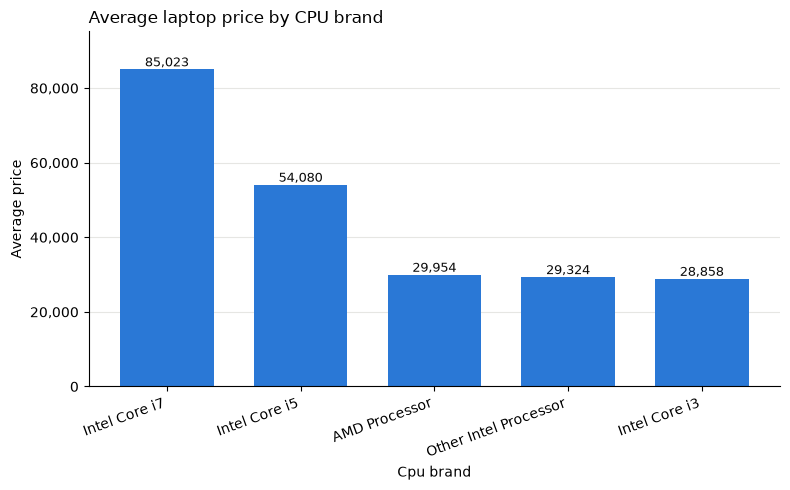

In [38]:
# Bar plot: average price per Cpu brand, most expensive first
cpu_price = df.groupby('Cpu brand')['Price'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False)
print(cpu_price.round(0))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(cpu_price.index, cpu_price['mean'], color='#2a78d6', width=0.7)
for bar, m in zip(bars, cpu_price['mean']):
    ax.text(bar.get_x() + bar.get_width() / 2, m, f'{m:,.0f}', ha='center', va='bottom', fontsize=9, color='#0b0b0b')

ax.set_title('Average laptop price by CPU brand', loc='left')
ax.set_xlabel('Cpu brand')
ax.set_ylabel('Average price')
ax.set_ylim(0, cpu_price['mean'].max() * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('cpu_brand_price.png', dpi=120)
plt.show()

## Drop `Cpu` and `Cpu Name`
Their information is captured in `Cpu brand`.

In [39]:
# Drop the raw CPU columns (errors="ignore" makes re-running safe)
print('Shape before:', df.shape)
df = df.drop(columns=['Cpu', 'Cpu Name'], errors='ignore')
print('Shape after: ', df.shape)
print(list(df.columns))
df.head()

Shape before: (1303, 14)
Shape after:  (1303, 12)
['Company', 'TypeName', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price', 'Touchscreen', 'Ips', 'ppi', 'Cpu brand']


,Company,TypeName,Ram,Memory,Gpu,OpSys,Weight,Price,Touchscreen,Ips,ppi,Cpu brand
0,Apple,Ultrabook,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832,0,1,226.983005,Intel Core i5
1,Apple,Ultrabook,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232,0,0,127.677940,Intel Core i5
2,HP,Notebook,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000,0,0,141.211998,Intel Core i5
3,Apple,Ultrabook,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360,0,1,220.534624,Intel Core i7
4,Apple,Ultrabook,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080,0,1,226.983005,Intel Core i5


## RAM vs Price

         mean  count
Ram                 
2     13553.0     22
4     30613.0    375
6     32778.0     41
8     62914.0    619
12    66037.0     25
16   103191.0    200
24   117553.0      3
32   181849.0     17
64   211788.0      1


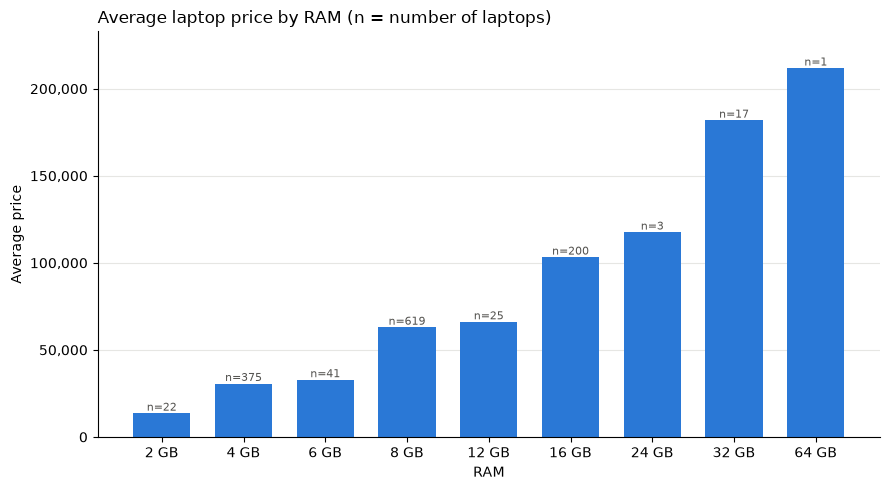

In [40]:
# Bar plot: average price for each RAM size (RAM shown as categories, in size order)
ram_price = df.groupby('Ram')['Price'].agg(['mean', 'count']).sort_index()
print(ram_price.round(0))

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f'{r} GB' for r in ram_price.index]
bars = ax.bar(labels, ram_price['mean'], color='#2a78d6', width=0.7)
for bar, (m, n) in zip(bars, ram_price.values):
    ax.text(bar.get_x() + bar.get_width() / 2, m, f'n={int(n)}', ha='center', va='bottom', fontsize=8, color='#52514e')

ax.set_title('Average laptop price by RAM (n = number of laptops)', loc='left')
ax.set_xlabel('RAM')
ax.set_ylabel('Average price')
ax.set_ylim(0, ram_price['mean'].max() * 1.1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('ram_price.png', dpi=120)
plt.show()

## Feature engineering: `SSD`, `HDD`, `Flash Storage`, `Hybrid` (from Memory)

In [41]:
# Parse Memory into 4 numeric columns (capacity in GB): SSD, HDD, Flash Storage, Hybrid
# e.g. '128GB SSD +  1TB HDD' -> SSD=128, HDD=1000, Flash Storage=0, Hybrid=0
import re

storage_types = ['SSD', 'HDD', 'Flash Storage', 'Hybrid']

def parse_memory(text):
    sizes = {t: 0 for t in storage_types}          # types not present stay 0
    for part in text.split('+'):                    # one part per drive
        part = part.strip()
        match = re.fullmatch(r'(\d+(?:\.\d+)?)(GB|TB) (SSD|HDD|Flash Storage|Hybrid)', part)
        if match is None:
            raise ValueError(f'Unexpected Memory format: {part!r} in {text!r}')
        size, unit, kind = match.groups()
        gb = float(size) * (1000 if unit == 'TB' else 1)   # TB -> GB
        sizes[kind] += int(gb)                              # add up if two drives of same type
    return pd.Series(sizes)

df[storage_types] = df['Memory'].apply(parse_memory)

In [42]:
# Verify: dtypes, missing values, shape
print(df[storage_types].dtypes)
print('Missing values:', df[storage_types].isnull().sum().to_dict())
print('Shape:', df.shape)

# How many laptops have each storage type (value > 0)
print('\nLaptops with each type:')
print((df[storage_types] > 0).sum())

# Correlation with Price
print('\nCorrelation with Price:')
print(df[storage_types].corrwith(df['Price']).round(3))

SSD              int64
HDD              int64
Flash Storage    int64
Hybrid           int64
dtype: object
Missing values: {'SSD': 0, 'HDD': 0, 'Flash Storage': 0, 'Hybrid': 0}
Shape: (1303, 16)

Laptops with each type:
SSD              843
HDD              576
Flash Storage     75
Hybrid            12
dtype: int64

Correlation with Price:
SSD              0.671
HDD             -0.096
Flash Storage   -0.041
Hybrid           0.008
dtype: float64


In [43]:
# Spot-check: one row for every distinct Memory string, including two-drive cases
df.drop_duplicates('Memory')[['Memory'] + storage_types].sort_values('Memory').reset_index(drop=True)

,Memory,SSD,HDD,Flash Storage,Hybrid
0,1.0TB HDD,0,1000,0,0
1,1.0TB Hybrid,0,0,0,1000
2,128GB Flash Storage,0,0,128,0
3,128GB HDD,0,128,0,0
4,128GB SSD,128,0,0,0
5,128GB SSD + 1TB HDD,128,1000,0,0
6,128GB SSD + 2TB HDD,128,2000,0,0
7,16GB Flash Storage,0,0,16,0
8,16GB SSD,16,0,0,0
9,180GB SSD,180,0,0,0


In [44]:
# Current state of the data
df.head()

,Company,TypeName,Ram,Memory,Gpu,OpSys,Weight,Price,Touchscreen,Ips,ppi,Cpu brand,SSD,HDD,Flash Storage,Hybrid
0,Apple,Ultrabook,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832,0,1,226.983005,Intel Core i5,128,0,0,0
1,Apple,Ultrabook,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232,0,0,127.677940,Intel Core i5,0,0,128,0
2,HP,Notebook,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000,0,0,141.211998,Intel Core i5,256,0,0,0
3,Apple,Ultrabook,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360,0,1,220.534624,Intel Core i7,512,0,0,0
4,Apple,Ultrabook,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080,0,1,226.983005,Intel Core i5,256,0,0,0


## Drop `Memory`
Its information is captured in `SSD`, `HDD`, `Flash Storage` and `Hybrid`.

In [45]:
# Drop the raw Memory column (errors="ignore" makes re-running safe)
print('Shape before:', df.shape)
df = df.drop(columns=['Memory'], errors='ignore')
print('Shape after: ', df.shape)
print(list(df.columns))

Shape before: (1303, 16)
Shape after:  (1303, 15)
['Company', 'TypeName', 'Ram', 'Gpu', 'OpSys', 'Weight', 'Price', 'Touchscreen', 'Ips', 'ppi', 'Cpu brand', 'SSD', 'HDD', 'Flash Storage', 'Hybrid']


In [46]:
# Correlation of every numeric column with Price, strongest first
price_corr = df.corr(numeric_only=True)['Price'].drop('Price').sort_values(ascending=False)
print(price_corr.round(3))

Ram              0.743
SSD              0.671
ppi              0.473
Ips              0.252
Weight           0.210
Touchscreen      0.191
Hybrid           0.008
Flash Storage   -0.041
HDD             -0.096
Name: Price, dtype: float64


## Drop `Hybrid` and `Flash Storage`
Near-zero correlation with Price and very few laptops have them.

In [47]:
# Drop the weak storage columns (errors="ignore" makes re-running safe)
print('Shape before:', df.shape)
df = df.drop(columns=['Hybrid', 'Flash Storage'], errors='ignore')
print('Shape after: ', df.shape)
print(list(df.columns))

Shape before: (1303, 15)
Shape after:  (1303, 13)
['Company', 'TypeName', 'Ram', 'Gpu', 'OpSys', 'Weight', 'Price', 'Touchscreen', 'Ips', 'ppi', 'Cpu brand', 'SSD', 'HDD']


## Feature engineering: `Gpu brand` (from Gpu)

In [48]:
# Gpu brand = first word of Gpu  (e.g. 'Nvidia GeForce GTX 1050' -> 'Nvidia')
df['Gpu brand'] = df['Gpu'].apply(lambda text: text.split()[0])

# Verify: counts, missing values, shape
print(df['Gpu brand'].value_counts())
print('Missing values:', df['Gpu brand'].isnull().sum())
print('Shape:', df.shape)

# Spot-check one example per brand
df.groupby('Gpu brand').head(1)[['Gpu', 'Gpu brand']]

Gpu brand
Intel     722
Nvidia    400
AMD       180
ARM         1
Name: count, dtype: int64
Missing values: 0
Shape: (1303, 14)


,Gpu,Gpu brand
0,Intel Iris Plus Graphics 640,Intel
3,AMD Radeon Pro 455,AMD
8,Nvidia GeForce MX150,Nvidia
1191,ARM Mali T860 MP4,ARM


## Drop the single ARM laptop
The Samsung laptop with an ARM CPU and ARM GPU is the only one of its kind (and was labelled "AMD Processor" in `Cpu brand`).

In [49]:
# Show the row being removed
print(df.loc[df['Gpu brand'] == 'ARM', ['Company', 'TypeName', 'Gpu', 'Cpu brand', 'Price']])

# Keep every row except the ARM one
print('Shape before:', df.shape)
df = df[df['Gpu brand'] != 'ARM']
print('Shape after: ', df.shape)

# Verify both brand columns are now clean
print(df['Gpu brand'].value_counts())
print(df['Cpu brand'].value_counts())

      Company            TypeName                Gpu      Cpu brand     Price
1191  Samsung  2 in 1 Convertible  ARM Mali T860 MP4  AMD Processor  35111.52
Shape before: (1303, 14)
Shape after:  (1302, 14)
Gpu brand
Intel     722
Nvidia    400
AMD       180
Name: count, dtype: int64
Cpu brand
Intel Core i7            527
Intel Core i5            423
Other Intel Processor    154
Intel Core i3            136
AMD Processor             62
Name: count, dtype: int64


              mean   median  count
Gpu brand                         
Nvidia     79381.0  66014.0    400
Intel      53718.0  47979.0    722
AMD        41327.0  36027.0    180


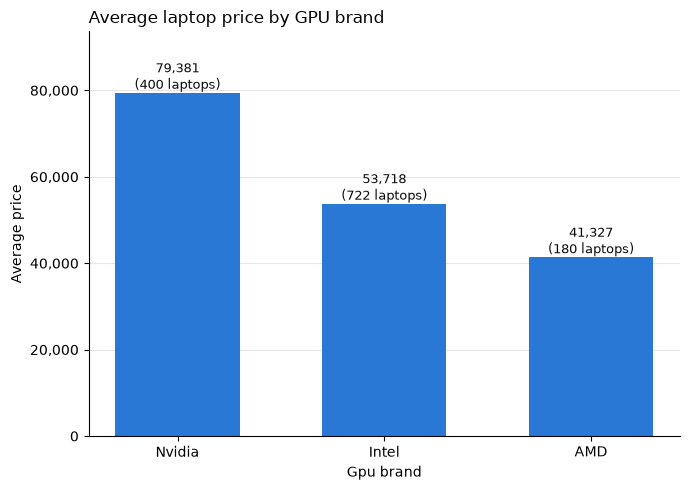

In [50]:
# Bar plot: average price per Gpu brand, most expensive first
gpu_price = df.groupby('Gpu brand')['Price'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False)
print(gpu_price.round(0))

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(gpu_price.index, gpu_price['mean'], color='#2a78d6', width=0.6)
for bar, (m, n) in zip(bars, gpu_price[['mean', 'count']].values):
    ax.text(bar.get_x() + bar.get_width() / 2, m, f'{m:,.0f}\n({int(n)} laptops)',
            ha='center', va='bottom', fontsize=9, color='#0b0b0b')

ax.set_title('Average laptop price by GPU brand', loc='left')
ax.set_xlabel('Gpu brand')
ax.set_ylabel('Average price')
ax.set_ylim(0, gpu_price['mean'].max() * 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('gpu_brand_price.png', dpi=120)
plt.show()

            median  count
Gpu brand                
Nvidia     66014.0    400
Intel      47979.0    722
AMD        36027.0    180


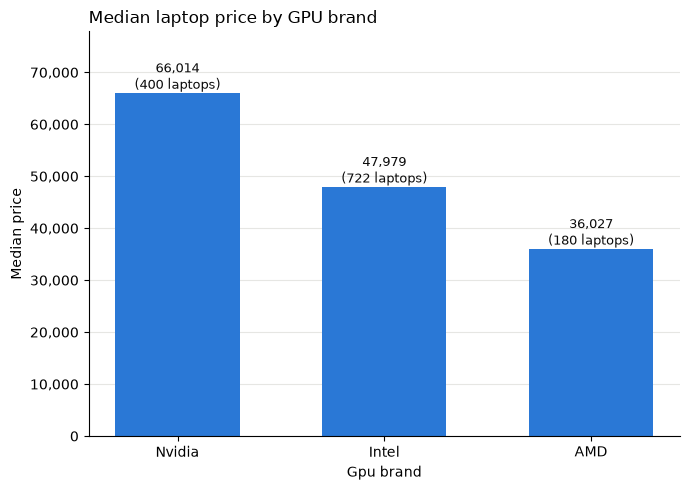

In [51]:
# Bar plot: MEDIAN price per Gpu brand (less affected by a few very expensive laptops than the mean)
gpu_median = df.groupby('Gpu brand')['Price'].agg(['median', 'count']).sort_values('median', ascending=False)
print(gpu_median.round(0))

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(gpu_median.index, gpu_median['median'], color='#2a78d6', width=0.6)
for bar, (m, n) in zip(bars, gpu_median.values):
    ax.text(bar.get_x() + bar.get_width() / 2, m, f'{m:,.0f}\n({int(n)} laptops)',
            ha='center', va='bottom', fontsize=9, color='#0b0b0b')

ax.set_title('Median laptop price by GPU brand', loc='left')
ax.set_xlabel('Gpu brand')
ax.set_ylabel('Median price')
ax.set_ylim(0, gpu_median['median'].max() * 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('gpu_brand_median_price.png', dpi=120)
plt.show()

## Drop `Gpu`
Its information is captured in `Gpu brand`.

In [52]:
# Drop the raw Gpu column (errors="ignore" makes re-running safe)
print('Shape before:', df.shape)
df = df.drop(columns=['Gpu'], errors='ignore')
print('Shape after: ', df.shape)
print(list(df.columns))

Shape before: (1302, 14)
Shape after:  (1302, 13)
['Company', 'TypeName', 'Ram', 'OpSys', 'Weight', 'Price', 'Touchscreen', 'Ips', 'ppi', 'Cpu brand', 'SSD', 'HDD', 'Gpu brand']


## OpSys vs Price

                 mean  count
OpSys                       
macOS         93220.0     13
Windows 7     89865.0     45
Windows 10 S  68544.0      8
Mac OS X      67286.0      8
Windows 10    62238.0   1072
Linux         32877.0     62
No OS         31327.0     66
Chrome OS     29279.0     26
Android       23124.0      2


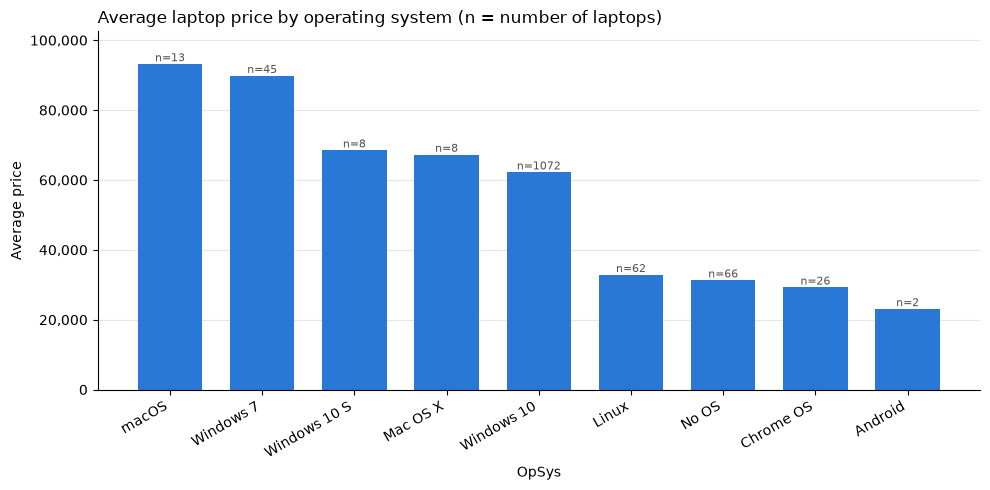

In [53]:
# Bar plot: average price per OpSys, most expensive first
os_price = df.groupby('OpSys')['Price'].agg(['mean', 'count']).sort_values('mean', ascending=False)
print(os_price.round(0))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(os_price.index, os_price['mean'], color='#2a78d6', width=0.7)
for bar, n in zip(bars, os_price['count']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'n={int(n)}',
            ha='center', va='bottom', fontsize=8, color='#52514e')

ax.set_title('Average laptop price by operating system (n = number of laptops)', loc='left')
ax.set_xlabel('OpSys')
ax.set_ylabel('Average price')
ax.set_ylim(0, os_price['mean'].max() * 1.1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('opsys_price.png', dpi=120)
plt.show()

## Feature engineering: `os` (from OpSys), then drop `OpSys`

In [54]:
# Group OpSys into 3 categories -> 'os'
def cat_os(inp):
    if inp in ('Windows 10', 'Windows 7', 'Windows 10 S'):
        return 'Windows'
    elif inp in ('macOS', 'Mac OS X'):
        return 'Mac'
    else:
        return 'Others/No OS/Linux'

df['os'] = df['OpSys'].apply(cat_os)

# Verify the mapping: every original OpSys value and the group it went to
print(df.groupby(['os', 'OpSys']).size())
print()
print(df['os'].value_counts())
print('Missing values:', df['os'].isnull().sum())

os                  OpSys       
Mac                 Mac OS X           8
                    macOS             13
Others/No OS/Linux  Android            2
                    Chrome OS         26
                    Linux             62
                    No OS             66
Windows             Windows 10      1072
                    Windows 10 S       8
                    Windows 7         45
dtype: int64

os
Windows               1125
Others/No OS/Linux     156
Mac                     21
Name: count, dtype: int64
Missing values: 0


In [55]:
# Average price per new os group
print(df.groupby('os')['Price'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False).round(0))

                       mean   median  count
os                                         
Mac                 83340.0  71379.0     21
Windows             63388.0  55891.0   1125
Others/No OS/Linux  31497.0  26587.0    156


In [56]:
# Drop the raw OpSys column (errors="ignore" makes re-running safe)
print('Shape before:', df.shape)
df = df.drop(columns=['OpSys'], errors='ignore')
print('Shape after: ', df.shape)
print(list(df.columns))
df.head()

Shape before: (1302, 14)
Shape after:  (1302, 13)
['Company', 'TypeName', 'Ram', 'Weight', 'Price', 'Touchscreen', 'Ips', 'ppi', 'Cpu brand', 'SSD', 'HDD', 'Gpu brand', 'os']


,Company,TypeName,Ram,Weight,Price,Touchscreen,Ips,ppi,Cpu brand,SSD,HDD,Gpu brand,os
0,Apple,Ultrabook,8,1.37,71378.6832,0,1,226.983005,Intel Core i5,128,0,Intel,Mac
1,Apple,Ultrabook,8,1.34,47895.5232,0,0,127.677940,Intel Core i5,0,0,Intel,Mac
2,HP,Notebook,8,1.86,30636.0000,0,0,141.211998,Intel Core i5,256,0,Intel,Others/No OS/Linux
3,Apple,Ultrabook,16,1.83,135195.3360,0,1,220.534624,Intel Core i7,512,0,AMD,Mac
4,Apple,Ultrabook,8,1.37,96095.8080,0,1,226.983005,Intel Core i5,256,0,Intel,Mac


## Weight distribution

count    1302.00
mean        2.04
std         0.67
min         0.69
25%         1.50
50%         2.04
75%         2.30
max         4.70
Name: Weight, dtype: float64
Skewness: 1.146


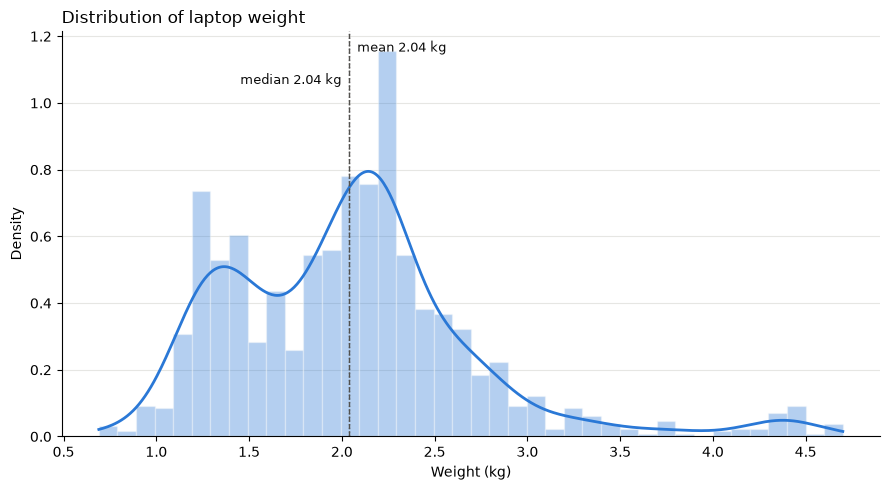

In [57]:
# Distribution plot of Weight (kg): histogram (density) + KDE curve
weight = df['Weight']
print(weight.describe().round(2))
print('Skewness:', round(weight.skew(), 3))

kde = gaussian_kde(weight)
xs = np.linspace(weight.min(), weight.max(), 500)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(weight, bins=40, density=True, color='#2a78d6', alpha=0.35, edgecolor='#fcfcfb', linewidth=1)
ax.plot(xs, kde(xs), color='#2a78d6', linewidth=2)

# Mark mean and median
ax.axvline(weight.mean(), color='#52514e', linestyle='--', linewidth=1)
ax.axvline(weight.median(), color='#52514e', linestyle=':', linewidth=1)
ax.text(weight.mean(), ax.get_ylim()[1] * 0.95, f'  mean {weight.mean():.2f} kg', color='#0b0b0b', fontsize=9)
ax.text(weight.median(), ax.get_ylim()[1] * 0.87, f'median {weight.median():.2f} kg  ', color='#0b0b0b', fontsize=9, ha='right')

ax.set_title('Distribution of laptop weight', loc='left')
ax.set_xlabel('Weight (kg)')
ax.set_ylabel('Density')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('weight_distribution.png', dpi=120)
plt.show()

## Weight vs Price

Correlation (Weight vs Price): 0.21


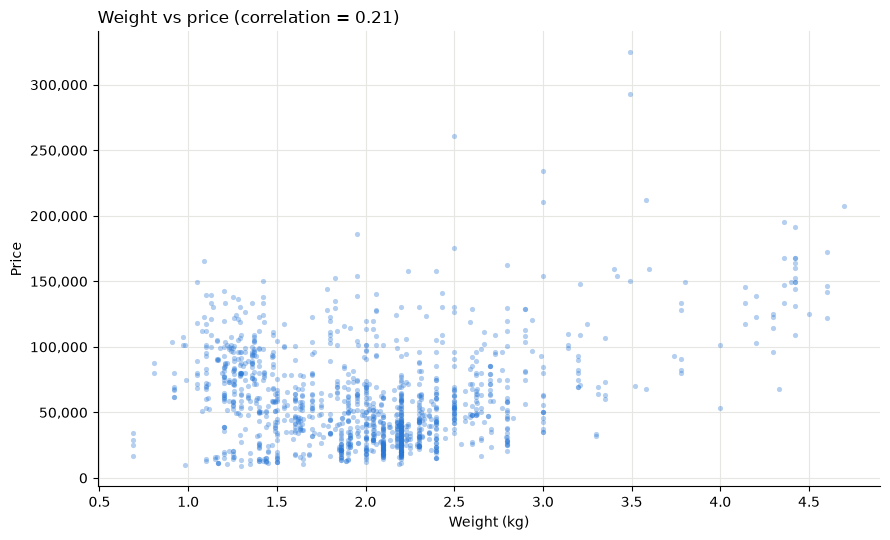

                mean  count
Weight                     
(0.0, 1.5]   69659.0    334
(1.5, 2.0]   52797.0    296
(2.0, 2.5]   45200.0    466
(2.5, 3.0]   67824.0    133
(3.0, 5.0]  123255.0     73


In [58]:
# Scatter plot: Weight vs Price
corr = df['Weight'].corr(df['Price'])
print('Correlation (Weight vs Price):', round(corr, 3))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(df['Weight'], df['Price'], s=14, color='#2a78d6', alpha=0.35, linewidths=0)

ax.set_title(f'Weight vs price (correlation = {corr:.2f})', loc='left')
ax.set_xlabel('Weight (kg)')
ax.set_ylabel('Price')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('weight_vs_price.png', dpi=120)
plt.show()

# Average price by weight band
bands = pd.cut(df['Weight'], bins=[0, 1.5, 2.0, 2.5, 3.0, 5.0])
print(df.groupby(bands, observed=True)['Price'].agg(['mean', 'count']).round(0))

## Correlation with Price (final numeric columns)

In [59]:
# Correlation of every numeric column with Price, strongest first
price_corr = df.corr(numeric_only=True)['Price'].drop('Price').sort_values(ascending=False)
print(price_corr.round(3))

Ram            0.743
SSD            0.671
ppi            0.475
Ips            0.253
Weight         0.210
Touchscreen    0.193
HDD           -0.097
Name: Price, dtype: float64


## Correlation heatmap

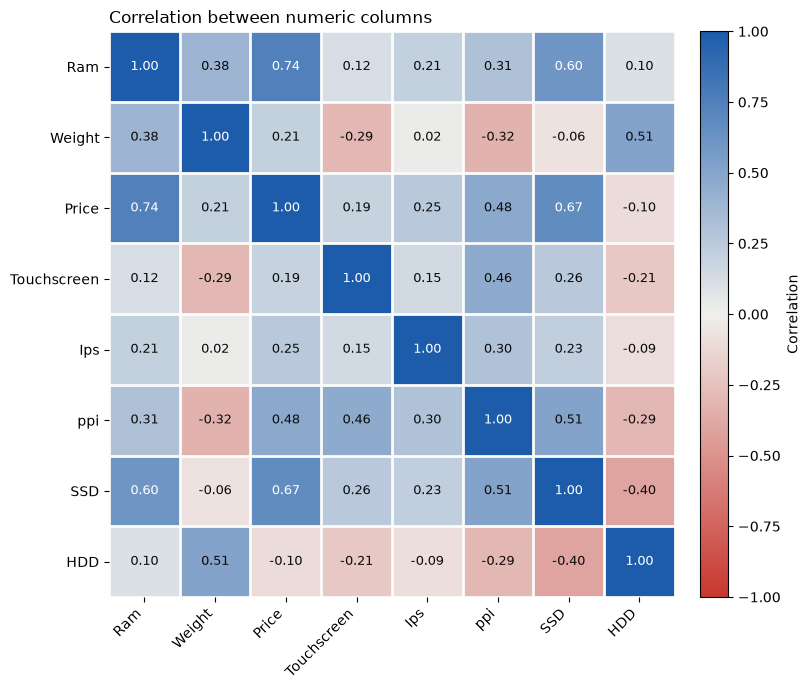

In [60]:
# Heatmap of the correlation matrix for all numeric columns
from matplotlib.colors import LinearSegmentedColormap

corr_matrix = df.corr(numeric_only=True)

# Diverging colours: red (negative) <- light gray (0) -> blue (positive), fixed range -1..1
cmap = LinearSegmentedColormap.from_list('div', ['#c7372f', '#f0efec', '#1c5cab'])

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr_matrix, cmap=cmap, vmin=-1, vmax=1)

# Write each correlation value in its cell (dark text on light cells, white on strong ones)
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        v = corr_matrix.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                color='white' if abs(v) > 0.6 else '#0b0b0b')

ax.set_xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr_matrix)), corr_matrix.columns)
ax.set_title('Correlation between numeric columns', loc='left')

# Thin white gaps between cells
ax.set_xticks(np.arange(-0.5, len(corr_matrix)), minor=True)
ax.set_yticks(np.arange(-0.5, len(corr_matrix)), minor=True)
ax.grid(which='minor', color='#fcfcfb', linewidth=2)
ax.tick_params(which='minor', length=0)
for s in ax.spines.values():
    s.set_visible(False)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Correlation')
plt.tight_layout()
fig.savefig('correlation_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

## Distribution of log(Price)

Skewness of Price:      1.52
Skewness of log(Price): -0.175
Mean / median of log(Price): 10.815 / 10.861


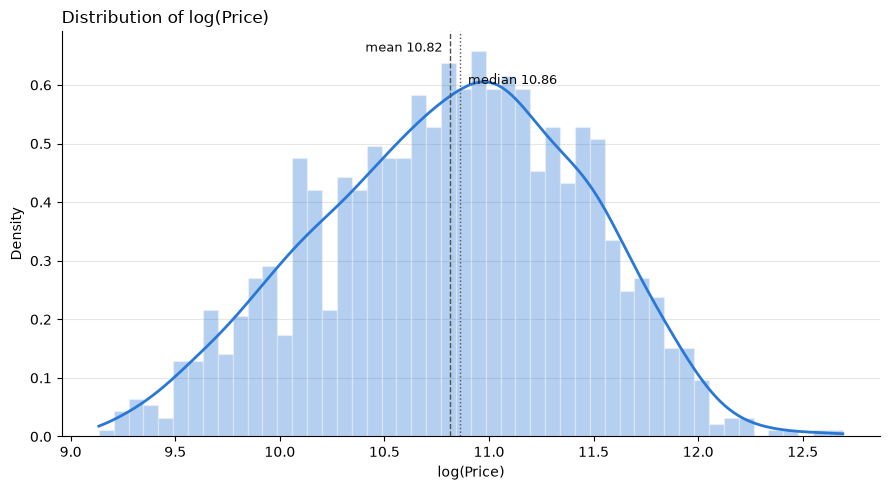

In [61]:
# Distribution plot of log(Price): histogram (density) + KDE curve
# (only for viewing - Price itself is NOT transformed here)
log_price = np.log(df['Price'])
print('Skewness of Price:     ', round(df['Price'].skew(), 3))
print('Skewness of log(Price):', round(log_price.skew(), 3))
print('Mean / median of log(Price):', round(log_price.mean(), 3), '/', round(log_price.median(), 3))

kde = gaussian_kde(log_price)
xs = np.linspace(log_price.min(), log_price.max(), 500)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(log_price, bins=50, density=True, color='#2a78d6', alpha=0.35, edgecolor='#fcfcfb', linewidth=1)
ax.plot(xs, kde(xs), color='#2a78d6', linewidth=2)

ax.axvline(log_price.mean(), color='#52514e', linestyle='--', linewidth=1)
ax.axvline(log_price.median(), color='#52514e', linestyle=':', linewidth=1)
ax.text(log_price.mean(), ax.get_ylim()[1] * 0.95, f'mean {log_price.mean():.2f}  ', color='#0b0b0b', fontsize=9, ha='right')
ax.text(log_price.median(), ax.get_ylim()[1] * 0.87, f'  median {log_price.median():.2f}', color='#0b0b0b', fontsize=9)

ax.set_title('Distribution of log(Price)', loc='left')
ax.set_xlabel('log(Price)')
ax.set_ylabel('Density')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('log_price_distribution.png', dpi=120)
plt.show()

# Model 1: Linear Regression
Target = log(Price); categorical columns one-hot encoded.

In [62]:
# Features and target
# X = every column except Price;  y = log(Price) (reduces the skew, see plot above)
X = df.drop(columns=['Price'])
y = np.log(df['Price'])

print('X shape:', X.shape)
print('y shape:', y.shape)
print('Feature columns:', list(X.columns))

X shape: (1302, 12)
y shape: (1302,)
Feature columns: ['Company', 'TypeName', 'Ram', 'Weight', 'Touchscreen', 'Ips', 'ppi', 'Cpu brand', 'SSD', 'HDD', 'Gpu brand', 'os']


In [63]:
# Train/test split: 15% of rows held out for testing, random_state=2 for reproducibility
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=2)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (1106, 12)  Test: (196, 12)


In [64]:
# Pipeline: one-hot encode the categorical columns, pass numeric columns through, then Linear Regression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

categorical_cols = ['Company', 'TypeName', 'Cpu brand', 'Gpu brand', 'os']

preprocessor = ColumnTransformer(
    transformers=[
        # drop='first' avoids the "dummy variable trap" for linear regression;
        # handle_unknown='ignore' lets the model cope with a category seen only in the test set
        ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_cols)
    ],
    remainder='passthrough'   # numeric columns (Ram, Weight, Touchscreen, Ips, ppi, SSD, HDD) unchanged
)

lr_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', LinearRegression())
])

lr_pipe.fit(X_train, y_train)
print('Number of features after one-hot encoding:', lr_pipe.named_steps['preprocess'].transform(X_train).shape[1])

Number of features after one-hot encoding: 38


In [65]:
# Evaluate on the test set
y_pred = lr_pipe.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae_log = mean_absolute_error(y_test, y_pred)
print('R2 score :', round(r2, 4))
print('MAE (log scale):', round(mae_log, 4))

# Same MAE converted back to real prices, for an easier-to-read number
mae_price = mean_absolute_error(np.exp(y_test), np.exp(y_pred))
print('MAE (actual price):', round(mae_price, 2))

R2 score : 0.8073
MAE (log scale): 0.2102
MAE (actual price): 12604.44


## Save the cleaned dataset
Used by `03_model_comparison.ipynb`.

In [66]:
# Save the fully cleaned / feature-engineered data (Price kept in original units)
df.to_csv('laptop_clean.csv', index=False)
print('Saved laptop_clean.csv with shape', df.shape)

Saved laptop_clean.csv with shape (1302, 13)
